# 02 · EDA Capa Silver: Reglas de Transformación, Anonimización y Cohorte Analítica
**Proyecto:** VIGÍA-VIH Medellín (2012–2023)  
**Arquitectura Medallion:** Capa `Silver` (`data/silver/notificaciones_silver.csv`, `data/silver/poblacion_analisis.csv`, `data/silver/_reporte_calidad.json`)  
**Autora:** Claudia Andrea Cifuentes Hincapié  

---
### Reglas de Transformación y Negocio Aplicadas en `Silver` (`src/etl.py`)
1. **Regla 5 (Deduplicación Longitudinal y Criterio de Cohorte):**
   - Se ordena establemente por `["id_persona", "fec_not"]` y se etiqueta `primera_notificacion = True` en el primer registro histórico de cada persona.
   - De **15.470** notificaciones se obtienen **14.881 personas únicas** (**569 personas** registran re-notificaciones equivalentes a **589 filas repetidas**).
   - Se filtra la **Población de Análisis ($N = 14.586$)** exigiendo simultáneamente: `primera_notificacion == True` $\land$ `residente_medellin == True` (`291` excluidos por residir fuera de Medellín) $\land$ `estadio.notna()` (`4` excluidos por estadio desconocido).
2. **Regla 6 (Construcción y Validez de Constructo del Desenlace `tardio`):**
   - Se define `tardio = True` cuando `estadio` es `SIDA` ($1.248$) o `Muerto` ($243$), sumando **1.491 casos de presentación avanzada (10,22%)** frente a **13.095 en estadio VIH (89,78%)**.
   - Se verifica su validez clínica: el **90,6%** de los casos SIDA presenta $\ge 1$ infección oportunista (vs. **0,15%** en VIH) y el **65,9%** requirió hospitalización (vs. **14,4%** en VIH).
3. **Regla 7 (Recodificación y Armonización Sociodemográfica/Territorial):**
   - `grupo_edad`: `<18`, `18-28`, `29-39`, `40-49`, `50-59`, `60+`.
   - `aseguramiento`: `Contributivo`, `Subsidiado`, `No asegurado`, `Especial/Excepción`, `Indeterminado`.
   - `mecanismo`: `Heterosexual`, `Homosexual`, `Bisexual`, `Perinatal`, `Otro/sin dato`.
   - `comuna`: Limpieza de espacios y marcado de `comuna_conocida` (`78,9%` con comuna válida; `21,1%` sin información).

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = PROJ_ROOT_OVERRIDE if "PROJ_ROOT_OVERRIDE" in globals() else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import config
from src import etl, estadistica as es

silver = pd.read_csv(config.DIR_SILVER / "notificaciones_silver.csv")
pob = pd.read_csv(config.DIR_SILVER / "poblacion_analisis.csv")
cal = json.loads((config.DIR_SILVER / "_reporte_calidad.json").read_text(encoding="utf-8"))

print(f"Dimensiones notificaciones_silver.csv : {silver.shape[0]:,} filas x {silver.shape[1]} columnas")
print(f"Dimensiones poblacion_analisis.csv    : {pob.shape[0]:,} filas x {pob.shape[1]} columnas")

Dimensiones notificaciones_silver.csv : 15,470 filas x 25 columnas
Dimensiones poblacion_analisis.csv    : 14,586 filas x 25 columnas


### 1. Diagrama Tabular de Atrición de la Cohorte (Bronze $\rightarrow$ Silver)

In [2]:
prim = silver[silver["primera_notificacion"]]
excl_mun = int((~prim["residente_medellin"]).sum())
excl_est = int((prim["residente_medellin"] & prim["estadio"].isna()).sum())

tabla_atricion = pd.DataFrame([
    {"Paso_Flujo": "1. Total notificaciones crudas e ingresadas a Silver", "N_Registros": int(len(silver)), "Excluidos": 0, "Criterio_Aplicado": "Base completa Evento 850"},
    {"Paso_Flujo": "2. Personas únicas (Primera notificación cronológica)", "N_Registros": int(len(prim)), "Excluidos": int(len(silver) - len(prim)), "Criterio_Aplicado": f"Deduplicación por id_persona ({cal['personas_con_renotificacion']} personas con >1 notif)"},
    {"Paso_Flujo": "3. Residentes en Medellín en su primera notificación", "N_Registros": int(len(prim) - excl_mun), "Excluidos": excl_mun, "Criterio_Aplicado": "Filtro nmun_resi == 'MEDELLIN'"},
    {"Paso_Flujo": "4. Población de Análisis (Con estadio clínico conocido)", "N_Registros": int(len(pob)), "Excluidos": excl_est, "Criterio_Aplicado": "Filtro est_cli in {'1': VIH, '2': SIDA, '3': Muerto}"}
])
display(tabla_atricion)

,Paso_Flujo,N_Registros,Excluidos,Criterio_Aplicado
0,1. Total notificaciones crudas e ingresadas a ...,15470,0,Base completa Evento 850
1,2. Personas únicas (Primera notificación crono...,14881,589,Deduplicación por id_persona (569 personas con...
2,3. Residentes en Medellín en su primera notifi...,14590,291,Filtro nmun_resi == 'MEDELLIN'
3,4. Población de Análisis (Con estadio clínico ...,14586,4,"Filtro est_cli in {'1': VIH, '2': SIDA, '3': M..."


### 2. Validez de Constructo de la Variable Desenlace (`tardio`)

In [3]:
val_constructo = pob.groupby("estadio").agg(
    Personas=("id_persona", "count"),
    Pct_Cohorte=("id_persona", lambda s: round(len(s) / len(pob) * 100, 2)),
    Pct_Infeccion_Oportunista=("n_oportunistas", lambda s: round((s > 0).mean() * 100, 2)),
    Pct_Hospitalizado=("hospitalizado", lambda s: round(s.astype(float).mean() * 100, 2)),
    Edad_Mediana=("edad_anios", "median")
).loc[["VIH", "SIDA", "Muerto"]].reset_index()
display(val_constructo)

,estadio,Personas,Pct_Cohorte,Pct_Infeccion_Oportunista,Pct_Hospitalizado,Edad_Mediana
0,VIH,13095,89.78,0.15,14.42,29.0
1,SIDA,1248,8.56,90.62,65.87,37.0
2,Muerto,243,1.67,92.18,92.18,39.0


### 3. EDA Univariado y Bivariado de Variables Analíticas en `poblacion_analisis.csv`

In [4]:
vars_cat = ["sexo", "grupo_edad", "aseguramiento", "mecanismo", "zona", "migrante", "fuente"]
res_bivariado = []
for v in vars_cat:
    g = pob.groupby(v, dropna=False).agg(n=("tardio", "size"), n_tardio=("tardio", "sum")).reset_index()
    g = g.rename(columns={v: "Categoria"})
    g.insert(0, "Variable", v)
    g["Pct_Total"] = (g["n"] / len(pob) * 100).round(1)
    g["Pct_Tardio"] = (g["n_tardio"] / g["n"] * 100).round(1)
    lo, hi = es.wilson(g["n_tardio"], g["n"])
    g["IC95_Inf"] = (lo * 100).round(1)
    g["IC95_Sup"] = (hi * 100).round(1)
    res_bivariado.append(g)

df_biv = pd.concat(res_bivariado, ignore_index=True)
display(df_biv)

,Variable,Categoria,n,n_tardio,Pct_Total,Pct_Tardio,IC95_Inf,IC95_Sup
0,sexo,Hombre,12373,1204,84.8,9.7,9.2,10.3
1,sexo,Mujer,2213,287,15.2,13.0,11.6,14.4
2,grupo_edad,18-28,6381,307,43.7,4.8,4.3,5.4
3,grupo_edad,29-39,4515,491,31.0,10.9,10.0,11.8
4,grupo_edad,40-49,1771,315,12.1,17.8,16.1,19.6
5,grupo_edad,50-59,1131,242,7.8,21.4,19.1,23.9
6,grupo_edad,60+,531,123,3.6,23.2,19.8,26.9
7,grupo_edad,<18,254,11,1.7,4.3,2.4,7.6
8,grupo_edad,NaN,3,2,0.0,66.7,20.8,93.9
9,aseguramiento,Contributivo,9400,700,64.4,7.4,6.9,8.0


### 4. Distribución de Edad Continua y Oportunidad de Notificación por Estadio Clínico

C:\Users\claud\AppData\Local\Temp\ipykernel_20640\386749388.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pob.dropna(subset=["edad_anios"]), x="estadio", y="edad_anios", order=["VIH", "SIDA", "Muerto"],


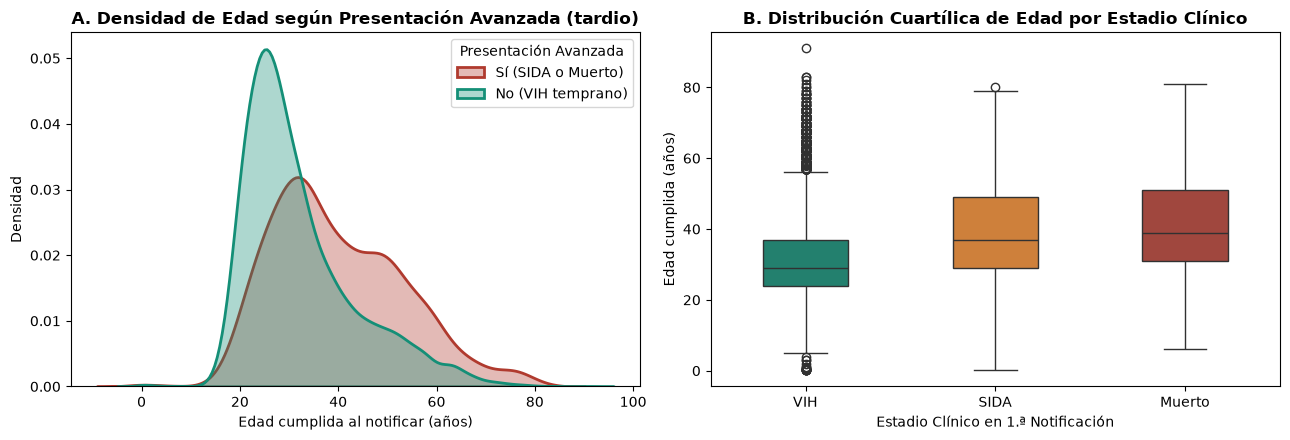

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel A: Distribución de edad por desenlace tardío
sns.kdeplot(data=pob.dropna(subset=["edad_anios"]), x="edad_anios", hue="tardio", common_norm=False,
            fill=True, palette={False: "#148F77", True: "#B03A2E"}, alpha=0.35, linewidth=2, ax=axes[0])
axes[0].set_title("A. Densidad de Edad según Presentación Avanzada (tardio)", fontweight="bold")
axes[0].set_xlabel("Edad cumplida al notificar (años)")
axes[0].set_ylabel("Densidad")
axes[0].legend(title="Presentación Avanzada", labels=["Sí (SIDA o Muerto)", "No (VIH temprano)"])

# Panel B: Boxplot de edad por estadio clínico
sns.boxplot(data=pob.dropna(subset=["edad_anios"]), x="estadio", y="edad_anios", order=["VIH", "SIDA", "Muerto"],
            palette=["#148F77", "#E67E22", "#B03A2E"], width=0.45, ax=axes[1])
axes[1].set_title("B. Distribución Cuartílica de Edad por Estadio Clínico", fontweight="bold")
axes[1].set_xlabel("Estadio Clínico en 1.ª Notificación")
axes[1].set_ylabel("Edad cumplida (años)")

plt.tight_layout()
plt.show()